# Ciputra Field Dex: reproducible GIS analysis

**Question:** at the same campus starting position, which creatures become catchable when the radius increases from 30 m to 60 m? All eight configured spawns participate, regardless of saved game catches. This offline notebook uses the same Python GIS functions as the game.

Run all cells with the project `.venv` kernel. Alternatively, from the project root run `.\.venv\Scripts\python.exe scripts/run_notebook.py` (requires `ipykernel` and `nbclient`). Tables and both maps are embedded below and also exported to `outputs/`.

## Layers, operations and units

The two main analysis layers are **named place points** (name and category, `data/editable/places.geojson`) and **synthetic Pokemon points** (authored in `backend/app/game/spawns.py`, exported to `outputs/pokemon.geojson`). Both point layers are saved as GeoJSON in EPSG:4326. Roads/buildings/landcover from OSM provide context; synthetic habitats and the playable boundary are supplementary.

1. **Buffer:** GeoPandas reprojects place points with `to_crs('EPSG:32749')`, then buffers every place by **20 m**. Shapely also builds 30/60 m player buffers. Capture uses exact planar distance <= radius, including its boundary.
2. **Spatial join:** `gpd.sjoin(pokemon, zones, how='left', predicate='intersects')` attaches place names to Pokemon. These results generate game hints (for example, Charizard ada di Hokky Supermarket). Boundary intersections count and overlaps retain multiple rows; catch totals use unique spawn IDs. A polygon buffer approximates a circle with 256 segments, so an exact analytic radius point between vertices can lie just outside the polygon.

Source longitude/latitude is **EPSG:4326 in degrees**. pyproj converts it to **EPSG:32749, UTM zone 49S in metres**, before buffers or distances are calculated. The game subtracts a fixed UTM origin for local east/north coordinates; the join adds that origin back. A translation preserves distances, but these local coordinates are not full UTM eastings/northings.

The start is the configured university reference position adjusted by the existing building-collision logic. We display the actual resulting point below rather than assuming it equals the reference pin.

In [1]:
from pathlib import Path
import sys
import math
import pandas as pd
from IPython.display import SVG, Markdown, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'config/game.yaml').exists(), 'Run from the project root or notebooks directory.'
sys.path.insert(0, str(ROOT))
from scripts.analyze import analyze
from backend.app.main import load_world
from backend.app.gis.coordinates import to_lonlat
from backend.app.gis.analysis import buffer_ring
from shapely.geometry import Polygon
world = load_world()
rows = analyze()
print('Python:', sys.executable)
print('Actual player start (local east, north metres):', tuple(round(v, 3) for v in world['start']))
print('Actual player start (longitude, latitude):', to_lonlat(*world['start']))
display(pd.DataFrame(rows))

Python: C:\Users\hamer\Documents\CollegeProjects\Comgraph\AFL2GIS\.venv\Scripts\python.exe
Actual player start (local east, north metres): (1.729, 9.691)
Actual player start (longitude, latitude): (112.63151533985429, -7.285543319106876)


,radius_m,unique_catchable,spawn_ids
0,30,1,[pikachu_01]
1,60,2,"[pikachu_01, squirtle_01]"


## Layer inventory and joined spawn results
The main layers are place points and Pokemon points. Additional polygons and roads are context. Distances below use the actual player start and are rounded only for display.

In [2]:
inventory = [{'layer': 'spawns', 'geometry': 'Point', 'features': len(world['spawns']), 'source': 'Synthetic'}]
for name, layer in world['layers'].items():
    inventory.append({'layer': name, 'geometry': ', '.join(sorted({f['geometry']['type'] for f in layer['features']})),
                      'features': len(layer['features']), 'source': 'Synthetic' if name in ('habitats', 'play_area') else ('Reference pins / OSM' if name == 'places' else ('Derived 20 m buffers' if name == 'place_zones' else 'OpenStreetMap'))})
display(pd.DataFrame(inventory))
spawns = pd.read_csv(ROOT / 'outputs/spawn_table.csv')
distance_by_id = {s['id']: math.dist(world['start'], (s['x'], s['y'])) for s in world['spawns']}
spawns['distance_to_player_m'] = spawns['id'].map(distance_by_id)
for row in rows:
    spawns[f'catchable_{row["radius_m"]}m'] = spawns['id'].isin(row['spawn_ids'])
display(spawns.round({'longitude': 7, 'latitude': 7, 'east_from_origin_m': 2, 'north_from_origin_m': 2, 'distance_to_player_m': 2}))

,layer,geometry,features,source
0,spawns,Point,8,Synthetic
1,paths,LineString,277,OpenStreetMap
2,buildings,Polygon,1572,OpenStreetMap
3,landcover,Polygon,7,OpenStreetMap
4,habitats,Polygon,2,Synthetic
5,play_area,Polygon,1,Synthetic
6,places,Point,8,Reference pins / OSM
7,place_zones,Polygon,8,Derived 20 m buffers


,id,species,longitude,latitude,east_from_origin_m,north_from_origin_m,habitats,places,hint,distance_to_player_m,catchable_30m,catchable_60m
0,pikachu_01,Pikachu,112.631626,-7.285558,14.00,8.00,Campus grove,Universitas Ciputra,Pikachu ada di Universitas Ciputra,12.39,True,True
1,bulbasaur_01,Bulbasaur,112.630686,-7.285374,-89.83,28.73,Campus grove,UC Loop,Bulbasaur ada di UC Loop,93.52,False,False
2,squirtle_01,Squirtle,112.631883,-7.285457,42.31,19.11,Campus grove,UC Apartment,Squirtle ada di UC Apartment,41.66,False,True
3,eevee_01,Eevee,112.633259,-7.285311,194.41,34.67,NaN,Pirates café,Eevee ada di Pirates café,194.29,False,False
4,jigglypuff_01,Jigglypuff,112.630366,-7.285084,-125.00,60.96,Campus grove,Indomaret,Jigglypuff ada di Indomaret,136.70,False,False
5,charizard_01,Charizard,112.633217,-7.285949,189.42,-35.90,NaN,Hokky Supermarket,Charizard ada di Hokky Supermarket,193.15,False,False
6,snorlax_01,Snorlax,112.634638,-7.281086,348.31,501.38,Hospital gardens,Ciputra Hospital,Snorlax ada di Ciputra Hospital,601.56,False,False
7,gengar_01,Gengar,112.634196,-7.281330,299.42,474.54,Hospital gardens,Ciputra Hospital B,Gengar ada di Ciputra Hospital B,552.00,False,False


## Named places and 20 m spatial join
Map keys P1-P8 refer to this table. Hokky/Apartment/Hospital use interior representative points of the retained OSM polygons; other OSM places use recorded nodes. The university retains the documented approximate reference pin. These are not verified entrances. UC Loop is an OSM bus stop; UC Walk and Plaza are not verified in this extract and have not been invented.

In [3]:
from backend.app.gis.places import place_analysis, PLACE_RADIUS_M
places, zones, joined, memberships = place_analysis(world['spawns'])
place_table = places.drop(columns='geometry').copy()
place_table.insert(0, 'map_key', [f'P{i}' for i in range(1, len(places) + 1)])
display(place_table[['map_key', 'name', 'category', 'coordinate_method']])
display(joined.drop(columns=['geometry', 'index_right']).reset_index(drop=True))
print('Place radius:', PLACE_RADIUS_M, 'metres')
print('Unique matched Pokemon:', joined.loc[joined.place_id.notna(), 'spawn_id'].nunique())
print('Exported point CRS:', pd.read_json(ROOT / 'outputs/pokemon.geojson', typ='series')['crs'])

,map_key,name,category,coordinate_method
0,P1,Universitas Ciputra,education,"Existing approximate reference pin, not an ent..."
1,P2,Hokky Supermarket,shopping,Interior representative point of projected OSM...
2,P3,UC Apartment,housing,Interior representative point of projected OSM...
3,P4,Ciputra Hospital,healthcare,Interior representative point of projected OSM...
4,P5,UC Loop,transport,Recorded OSM node
5,P6,Indomaret,shopping,Recorded OSM node
6,P7,Pirates café,food,Recorded OSM node
7,P8,Ciputra Hospital B,transport,Recorded OSM node


,spawn_id,place_id,place_name,category
0,pikachu_01,university,Universitas Ciputra,education
1,bulbasaur_01,uc_loop,UC Loop,transport
2,squirtle_01,apartment,UC Apartment,housing
3,eevee_01,pirates,Pirates café,food
4,jigglypuff_01,indomaret,Indomaret,shopping
5,charizard_01,hokky,Hokky Supermarket,shopping
6,snorlax_01,hospital,Ciputra Hospital,healthcare
7,gengar_01,hospital_bus,Ciputra Hospital B,transport


Place radius: 20 metres
Unique matched Pokemon: 8
Exported point CRS: {'type': 'name', 'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}}


## Buffer evidence
The areas below are measured from the same 256-segment buffer polygons used in the maps. Their units are square metres. Polygon areas approximate the theoretical circle areas; catch selection still uses exact distance.

In [4]:
display(pd.DataFrame([{'radius_m': row['radius_m'],
                       'buffer_area_m2': Polygon(buffer_ring(world['start'], row['radius_m'])).area,
                       'circle_area_m2': math.pi * row['radius_m'] ** 2}
                      for row in rows]).round(2))

,radius_m,buffer_area_m2,circle_area_m2
0,30,2827.15,2827.43
1,60,11308.60,11309.73


## Geographic overview
North is up. Both rings share the actual player start. The overview shows all eight spawns across the campus and hospital; the campus close-up below makes the radius change legible.

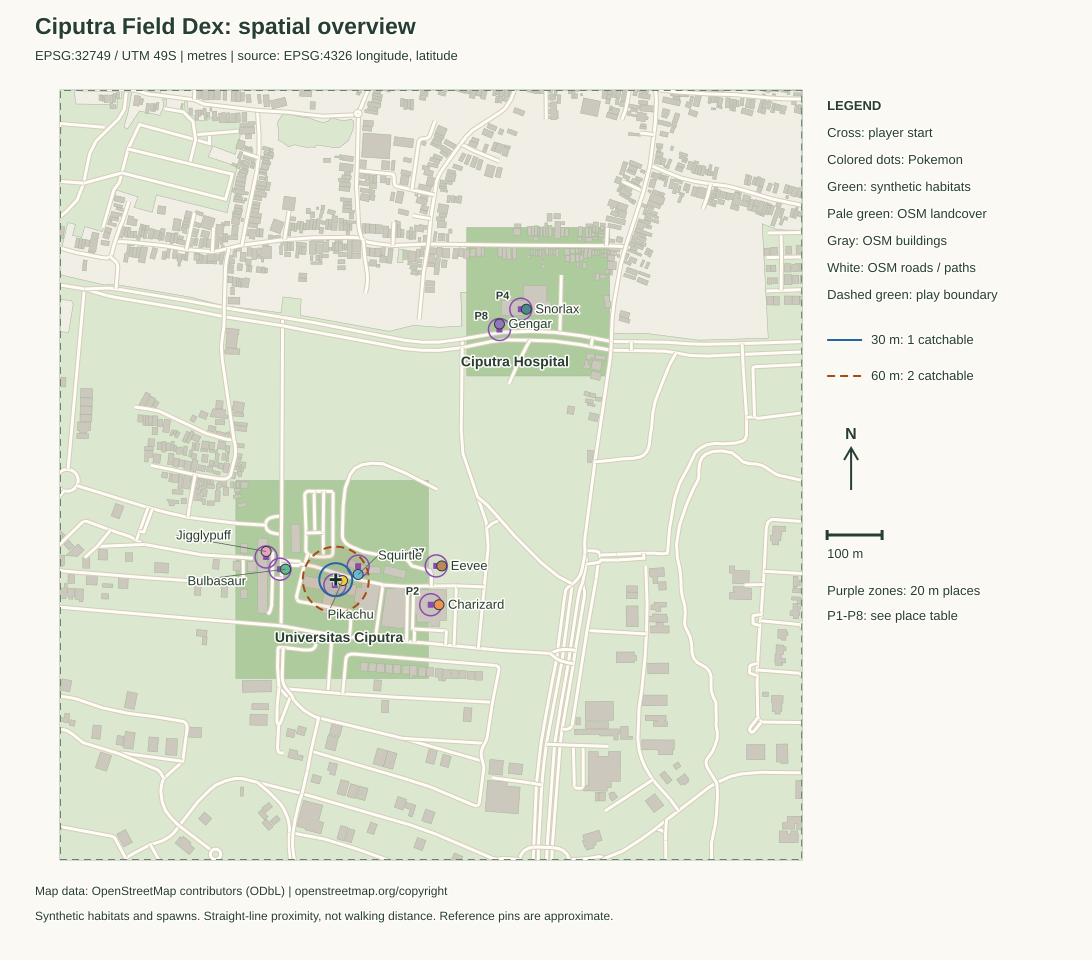

In [5]:
display(SVG(filename=str(ROOT / 'outputs/analysis_map.svg')))

## Campus close-up
Solid blue is the baseline radius; dashed orange is the alternative. Each scale bar is specific to its own map. Features outside this close-up remain part of the analysis.

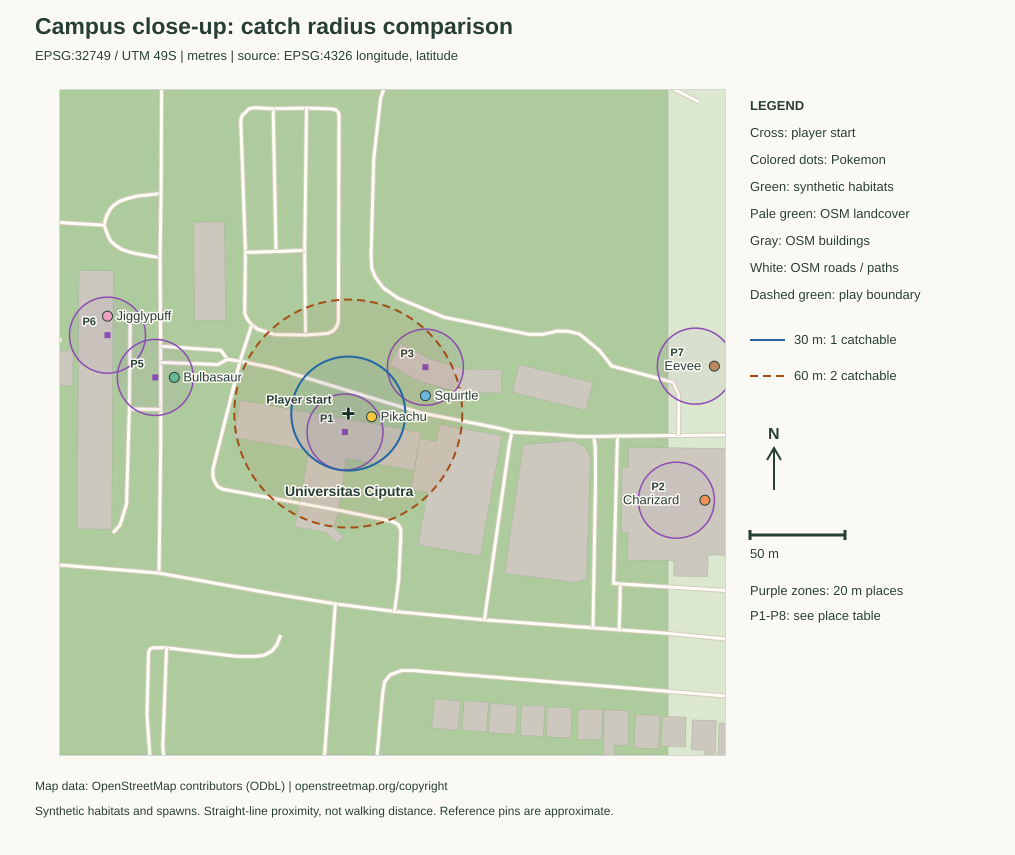

In [6]:
display(SVG(filename=str(ROOT / 'outputs/analysis_detail.svg')))

## Observed scenario results
The following explanation is generated from this run, so changes to configuration or spawn positions are reflected honestly.

In [7]:
baseline, alternative = rows
added = set(alternative['spawn_ids']) - set(baseline['spawn_ids'])
removed = set(baseline['spawn_ids']) - set(alternative['spawn_ids'])
by_id = {s['id']: s['species'] for s in world['spawns']}
def names(ids):
    return ', '.join(by_id[i] for i in sorted(ids)) or 'none'
shift = math.dist(world['start'], next(p['position'] for p in world['landmarks'] if p['id'] == world['config']['start_landmark']))
display(Markdown(f"At **{baseline['radius_m']} m**, **{baseline['unique_catchable']}** spawn(s) are catchable: {names(baseline['spawn_ids'])}. "
                 f"At **{alternative['radius_m']} m**, **{alternative['unique_catchable']}** are catchable: {names(alternative['spawn_ids'])}. "
                 f"Added: **{names(added)}**. Removed: **{names(removed)}**. "
                 f"The collision-safe start is **{shift:.2f} m** from the configured reference pin. "
                 "Player location, spawn positions and habitats are held constant; only the radius changes."))
for spawn_id in sorted(set(baseline['spawn_ids']) | set(alternative['spawn_ids'])):
    print(f'{by_id[spawn_id]}: {distance_by_id[spawn_id]:.2f} m from player')

At **30 m**, **1** spawn(s) are catchable: Pikachu. At **60 m**, **2** are catchable: Pikachu, Squirtle. Added: **Squirtle**. Removed: **none**. The collision-safe start is **9.84 m** from the configured reference pin. Player location, spawn positions and habitats are held constant; only the radius changes.

Pikachu: 12.39 m from player
Squirtle: 41.66 m from player


## Interpretation, provenance and limitations

The larger player radius changes catch eligibility, not place membership. Catch distance is straight-line distance and may pass through buildings; it is not walking distance or proof of access. The analysis does not modify gameplay saves.

**Proposal alignment:** named place points, 20 m place buffers, Pokemon/place joins and live game hints are now implemented. Spawn offsets were explicitly moved into named place zones, with Charizard at Hokky. Coordinates are fictional Pokemon placements around documented real-world reference points; no claim of surveyed accuracy is made. Place examples without verified coordinates (UC Walk/Plaza) are omitted. UC Loop remains a separate recorded bus stop, not a synonym for UC Walk.

Before this change, the habitat-only version gave Pikachu at 30 m and added Squirtle at 60 m. The cells above report the actual rerun after the placement change; counts are not forced to equal that earlier result. Inspect the distance table for the changed positions.

OSM coverage can be incomplete or outdated; the importer does not assemble multipolygon relations. Large places are simplified to points. `data/sources.md`, `data/original/download_metadata.json` and each place feature record provenance. Map data: OpenStreetMap contributors, ODbL. The notebook/CSV/GeoJSON/SVG outputs are reproducible with `scripts/run_notebook.py`. No routing, GPS or external map API is required for this milestone.